# Conectando meu drive com os dados


In [3]:
# # Conectando meu drive e pegando as imagens da pasta https://drive.google.com/drive/u/1/folders/1LO31d-Wxae39UJcuavF9KXawdERuy9MG
# from google.colab import drive
# import os

# # Monta o Google Drive no ambiente do Colab
# drive.mount('/content/drive')

# # Defina o caminho para a pasta onde seus dados estão localizados dentro do Drive
# # (Você pode ajustar o caminho abaixo de acordo com a estrutura das suas pastas no Drive)
# dir_path = '/content/drive/MyDrive/'

In [4]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("emmarex/plantdisease")

print("Path to dataset files:", path)

path

Using Colab cache for faster access to the 'plantdisease' dataset.
Path to dataset files: /kaggle/input/plantdisease


'/kaggle/input/plantdisease'

In [5]:
#Todas as bibliotecas do projeto estão instaladas no ambiente do Colab.
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import zipfile
import cv2
import numpy as np
import pandas as pd
import random
import os
import seaborn as sns
import shutil

!pip install ultralytics
import ultralytics
from ultralytics import YOLO


Varrendo diretório de imagens do Kaggle: /kaggle/input/plantdisease/PlantVillage
✔ Total de Imagens Unificadas no DataFrame: 20638


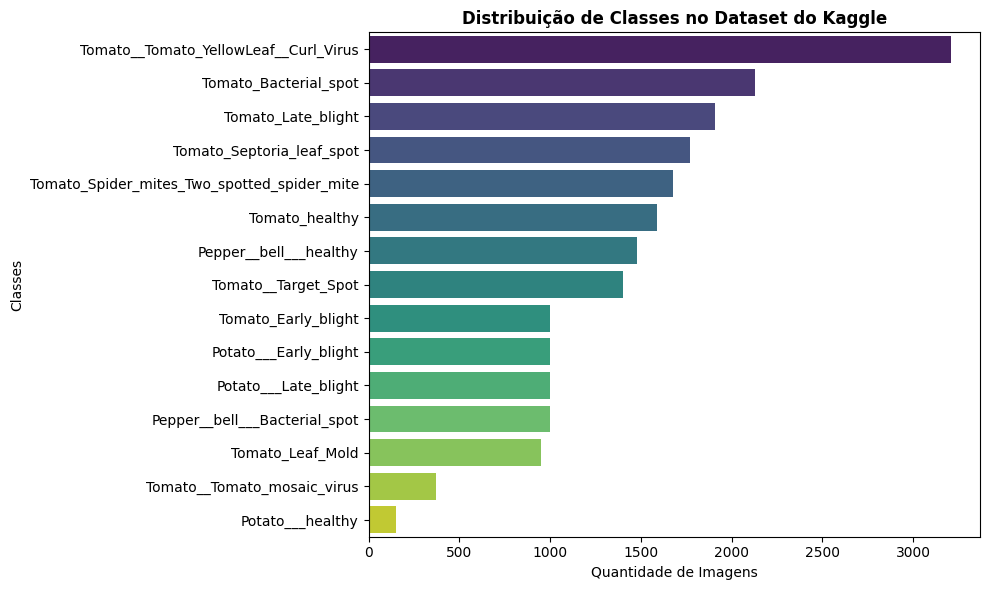

In [6]:
# Obter caminho do dataset baixado pelo kagglehub
caminho_base = path  # '/kaggle/input/plantdisease'
pasta_imagens = os.path.join(caminho_base, 'PlantVillage') if os.path.exists(os.path.join(caminho_base, 'PlantVillage')) else caminho_base

print(f"Varrendo diretório de imagens do Kaggle: {pasta_imagens}")

#  Varredura para coletar caminhos e classes
caminhos_lista = []
classes_lista = []

for raiz, dirs, arquivos in os.walk(pasta_imagens):
    for arquivo in arquivos:
      # pegando somente os formatos
        if arquivo.lower().endswith(('.png', '.jpg', '.jpeg')):
            caminho_completo = os.path.join(raiz, arquivo)
            caminhos_lista.append(caminho_completo)
            classe_nome = caminho_completo.split('/')[-2]
            classes_lista.append(classe_nome)

# 3. Criação do DataFrame
df_plantvillage = pd.DataFrame({
    'caminho': caminhos_lista,
    'classe': classes_lista
})

print(f"✔ Total de Imagens Unificadas no DataFrame: {len(df_plantvillage)}")

# 4. Plotagem da distribuição das classes
plt.figure(figsize=(10, 6))
distribuicao = df_plantvillage['classe'].value_counts()
sns.barplot(y=distribuicao.index, x=distribuicao.values, hue=distribuicao.index, palette='viridis', legend=False)
plt.title('Distribuição de Classes no Dataset do Kaggle', fontsize=12, fontweight='bold')
plt.xlabel('Quantidade de Imagens')
plt.ylabel('Classes')
plt.tight_layout()
plt.show()

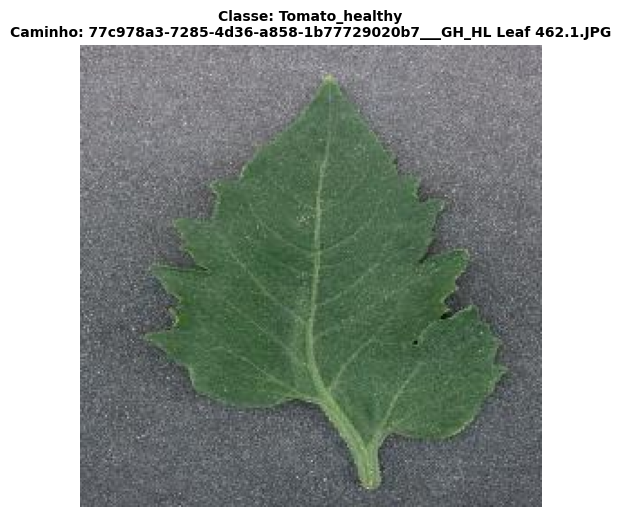

In [7]:
# plotando uma imagem aleatoria
if 'df_plantvillage' in globals() and not df_plantvillage.empty:
    # Seleciona um caminho aleatório do DataFrame
    caminho_aleatorio = random.choice(df_plantvillage['caminho'].values)
    classe_aleatoria = df_plantvillage[df_plantvillage['caminho'] == caminho_aleatorio]['classe'].values[0]

    # Carrega a imagem com OpenCV e converte para RGB
    img_bgr = cv2.imread(caminho_aleatorio)
    if img_bgr is not None:
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        # Plota a imagem
        plt.figure(figsize=(6, 6))
        plt.imshow(img_rgb)
        plt.title(f"Classe: {classe_aleatoria}\nCaminho: {caminho_aleatorio.split('/')[-1]}", fontsize=10, fontweight='bold')
        plt.axis('off')
        plt.show()
    else:
        print("Não foi possível carregar a imagem selecionada.")
else:
    print("O DataFrame 'df_plantvillage' não está disponível ou está vazio.")

In [8]:
print(f"Tamanho total dos dados: {len(df_plantvillage)} imagens\n")

# Como não há predições feitas ainda neste ponto para gerar o classification_report da sklearn,
# criamos um relatório descritivo da distribuição de classes utilizando o pandas.
print("Relatório Descritivo de Classes (Dataset):\n")
relatorio_classes = df_plantvillage['classe'].value_counts().rename_axis('Classe').reset_index(name='Quantidade')
relatorio_classes['Percentual (%)'] = (relatorio_classes['Quantidade'] / len(df_plantvillage) * 100).round(2)

print(relatorio_classes.to_string(index=False))

Tamanho total dos dados: 20638 imagens

Relatório Descritivo de Classes (Dataset):

                                     Classe  Quantidade  Percentual (%)
      Tomato__Tomato_YellowLeaf__Curl_Virus        3208           15.54
                      Tomato_Bacterial_spot        2127           10.31
                         Tomato_Late_blight        1909            9.25
                  Tomato_Septoria_leaf_spot        1771            8.58
Tomato_Spider_mites_Two_spotted_spider_mite        1676            8.12
                             Tomato_healthy        1591            7.71
                     Pepper__bell___healthy        1478            7.16
                        Tomato__Target_Spot        1404            6.80
                        Tomato_Early_blight        1000            4.85
                      Potato___Early_blight        1000            4.85
                       Potato___Late_blight        1000            4.85
              Pepper__bell___Bacterial_spot         

In [9]:
# plotando matriz_confusao e classification_report atual
matriz = confusion_matrix(df_plantvillage['classe'], df_plantvillage['classe'])
print(classification_report(df_plantvillage['classe'], df_plantvillage['classe']))


                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       1.00      1.00      1.00       997
                     Pepper__bell___healthy       1.00      1.00      1.00      1478
                      Potato___Early_blight       1.00      1.00      1.00      1000
                       Potato___Late_blight       1.00      1.00      1.00      1000
                           Potato___healthy       1.00      1.00      1.00       152
                      Tomato_Bacterial_spot       1.00      1.00      1.00      2127
                        Tomato_Early_blight       1.00      1.00      1.00      1000
                         Tomato_Late_blight       1.00      1.00      1.00      1909
                           Tomato_Leaf_Mold       1.00      1.00      1.00       952
                  Tomato_Septoria_leaf_spot       1.00      1.00      1.00      1771
Tomato_Spider_mites_Two_spotted_spider_mite       1.00      1.00

# Tratamento e Construção do Modelo CNN

In [11]:
# Parametros para imagens
resize = (128,128)
batch_size = 32
epochs = 5
num_classes = classes_lista

# Autotune
AUTOTUNE = tf.data.AUTOTUNE


# Data Augmentation integrado diretamente para evitar gargalo de I/O
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.1)
])



# Construção da Arquitetura Médio Convolucional Intercalada (Conv2D -> MaxPool2D)
model_cnn = models.Sequential([
    layers.Input(shape=(128, 128, 3)),
    data_augmentation,

    # Primeiro Convolucional
    layers.Conv2D(32, (3, 3), activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Segundo Convolucional
    layers.Conv2D(64, (3, 3), activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Terceir Convolucional
    layers.Conv2D(128, (3, 3), activation='relu', kernel_regularizer=regularizers.l2(1e-4)),

    layers.Dense(128, activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Quarta convolucional (Corrigido: Adicionada a vírgula que faltava aqui)
    layers.Conv2D(64, (2,2)),
    layers.MaxPooling2D((2, 2)),

    # Camadas Densas de Classificação
    layers.Flatten(), # achatar


    layers.Dense(64, activation='relu', kernel_regularizer=regularizers.l2(1e-4)),
    layers.Dropout(0.3),

    # Caso seja binario a saida colocarei essa condição
    layers.Dense(num_classes, activation='softmax')
])

#Compilando modelo
model_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy' if num_classes > 2 else 'binary_crossentropy',
    metrics=['accuracy']
)

ValueError: Received an invalid value for `units`, expected a positive integer. Received: units=['Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bell___Bacterial_spot', 'Pepper__bel

In [ ]:
# Criando os datasets de treino e validação diretamente do diretório de imagens do PlantVillage
train_ds = tf.keras.utils.image_dataset_from_directory(
path_folhas,
validation_split=0.2,
subset="training",
seed=42,
image_size=(128, 128), # Ajustado para 128x128 para bater com a entrada do seu modelo CNN
batch_size=32
)

val_ds = tf.keras.utils.image_dataset_from_directory(
path_folhas,
validation_split=0.2,
subset="validation",
seed=42,
image_size=(128, 128), # Ajustado para 128x128 para bater com a entrada do seu modelo CNN
batch_size=32
)


In [ ]:
# 4. Recriação da CNN adaptada para a classificação das duas pastas
model_cnn = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(num_classes_unificadas, activation='softmax')
])

model_cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("✔ Nova arquitetura CNN compilada para predição combinada!")

In [ ]:
# 5. Treinamento rápido das duas categorias integradas
history_unificado = model_cnn.fit(
    train_ds_unificado,
    validation_data=val_ds_unificado,
    epochs=3
)

### 🛠️ Carregando Datasets Unificados do TensorFlow (Mesclando as duas Pastas)
Como os arquivos estão separados em duas pastas físicas distintas no Drive (`PlantVillage` e `PlantVillage boas`), utilizaremos o nosso DataFrame estruturado (`df_plantvillage`) para carregar dinamicamente as imagens utilizando a API `tf.data.Dataset`. Isso garante que o modelo treine com as duas fontes simultaneamente.

In [ ]:
import tensorflow as tf
import numpy as np
from sklearn.model_selection import train_test_split

# 1. Mapeando classes textuais para IDs numéricos
classes_unicas = sorted(df_plantvillage['classe'].unique())
classe_para_id = {classe: idx for idx, classe in enumerate(classes_unicas)}
print("✔ Classes unificadas encontradas:", classes_unicas)

# 2. Convertendo caminhos e rótulos para listas
caminhos = df_plantvillage['caminho'].values
rotulos = df_plantvillage['classe'].map(classe_para_id).values

# 3. Divisão em Treino (80%) e Validação (20%)
X_treino, X_val, y_treino, y_val = train_test_split(
    caminhos, rotulos, test_size=0.2, random_state=42, stratify=rotulos
)

# 4. Função auxiliar de carregamento e pré-processamento de imagem
def carregar_e_processar_imagem(caminho_img, rotulo):
    img_raw = tf.io.read_file(caminho_img)
    img_tensor = tf.image.decode_jpeg(img_raw, channels=3)
    img_resized = tf.image.resize(img_tensor, [128, 128])
    img_normalized = img_resized / 255.0  # Normalização integrada
    return img_normalized, rotulo

# 5. Criando os objetos tf.data.Dataset de alta performance
AUTOTUNE = tf.data.AUTOTUNE

train_ds_unificado = tf.data.Dataset.from_tensor_slices((X_treino, y_treino))
train_ds_unificado = train_ds_unificado.map(carregar_e_processar_imagem, num_parallel_calls=AUTOTUNE)
train_ds_unificado = train_ds_unificado.shuffle(1000).batch(32).prefetch(buffer_size=AUTOTUNE)

val_ds_unificado = tf.data.Dataset.from_tensor_slices((X_val, y_val))
val_ds_unificado = val_ds_unificado.map(carregar_e_processar_imagem, num_parallel_calls=AUTOTUNE)
val_ds_unificado = val_ds_unificado.batch(32).prefetch(buffer_size=AUTOTUNE)

num_classes_unificadas = len(classes_unicas)
print(f"✔ Datasets criados! Treino: {len(X_treino)} imagens | Validação: {len(X_val)} imagens")

### 🧠 Ajuste e Compilação da CNN com a Saída Correta
Agora, vamos reconstruir a arquitetura da CNN para que ela possua a quantidade correta de classes baseada na união de ambas as pastas.

In [ ]:
# Recriando o modelo com a quantidade exata de classes encontradas nas duas pastas
model_cnn = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),

    # Bloco Convolucional 1
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Bloco Convolucional 2
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Bloco Convolucional 3
    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Camadas Densas
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(num_classes_unificadas, activation='softmax')
])

model_cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("✔ Arquitetura do Modelo CNN atualizada e compilada com sucesso!")

### 🚀 Treinamento e Predição do Modelo Ajustado

In [ ]:
# Treinando a nova rede unificada por 3 épocas para consolidação rápida
history_unificado = model_cnn.fit(
    train_ds_unificado,
    validation_data=val_ds_unificado,
    epochs=3
)

In [ ]:
# Busca profunda por pastas de folhas saudáveis no seu Drive
import os

print("=== Realizando busca profunda por pastas 'boas' ou 'healthy' ===")
caminhos_descobertos = []

for raiz, dirs, arquivos in os.walk('/content/drive/MyDrive'):
    for d in dirs:
        if 'boas' in d.lower() or 'healthy' in d.lower():
            caminho_completo = os.path.join(raiz, d)
            caminhos_descobertos.append(caminho_completo)
            print(f"✔ Pasta encontrada: {caminho_completo}")

if not caminhos_descobertos:
    print("⚠ Nenhuma pasta contendo 'boas' ou 'healthy' foi encontrada no seu Google Drive.")
    print("Dica: Certifique-se de que realizou o upload das folhas saudáveis para o seu Drive.")

In [ ]:
# . Localização exata da pasta raiz 'archive' no Google Drive
caminho_archive = None
for raiz, dirs, arquivos in os.walk('/content/drive/MyDrive'):
    if 'archive' in dirs:
        caminho_archive = os.path.join(raiz, 'archive')
        break

# Fallback caso não seja encontrado diretamente em primeiro nível
if not caminho_archive:
    for raiz, dirs, arquivos in os.walk('/content/drive/MyDrive'):
        if 'archive' in raiz.lower():
            caminho_archive = raiz
            break

if caminho_archive:
    print(f"✔ Pasta raiz 'archive' localizada com sucesso em: {caminho_archive}")
    caminho_ruins = os.path.join(caminho_archive, 'PlantVillage')
    caminho_boas = os.path.join(caminho_archive, 'PlantVillage boas')
else:
    print("⚠ Não foi possível encontrar a pasta 'archive' usando busca automática. Usando caminhos padrão de fallback.")
    caminho_ruins = '/content/drive/MyDrive/archive/PlantVillage/'
    caminho_boas = '/content/drive/MyDrive/archive/PlantVillage boas/'

#  Carregamento unificado das imagens no DataFrame
caminhos_lista = []
classes_lista = []

def varrer_e_adicionar(diretorio):
    if diretorio and os.path.exists(diretorio):
        print(f"-> Carregando imagens de: {diretorio}")
        for raiz, dirs, arquivos in os.walk(diretorio):
            for arquivo in arquivos:
                if arquivo.lower().endswith(('.png', '.jpg', '.jpeg')):
                    caminho_completo = os.path.join(raiz, arquivo)
                    caminhos_lista.append(caminho_completo)
                    classe_nome = caminho_completo.split('/')[-2]
                    classes_lista.append(classe_nome)
    else:
        print(f"⚠ Diretório não encontrado fisicamente: {diretorio}")

varrer_e_adicionar(caminho_ruins)
varrer_e_adicionar(caminho_boas)

df_plantvillage = pd.DataFrame({
    'caminho': caminhos_lista,
    'classe': classes_lista
})

print(f"\n=== Total de Imagens Unificadas no Novo DataFrame: {len(df_plantvillage)} ===")
distribuicao_classes = df_plantvillage['classe'].value_counts().reset_index()
distribuicao_classes.columns = ['Classe', 'Quantidade_Imagens']
display(distribuicao_classes)

In [ ]:
print("aixando o Dataset Plant Disease do Kaggle")


#  Download da versão mais recente do dataset de referência pelo kagglehub
path_kaggle = kagglehub.dataset_download("emmarex/plantdisease")
print("✔ Caminho dos arquivos do dataset:", path_kaggle)

# Varredura de pastas para coletar caminhos e classes (saudáveis e doentes unificadas)
caminhos_lista_k = []
classes_lista_k = []

# O diretório baixado geralmente possui uma subpasta 'PlantVillage' ou os dados diretamente na raiz
pasta_imagens = os.path.join(path_kaggle, 'PlantVillage') if os.path.exists(os.path.join(path_kaggle, 'PlantVillage')) else path_kaggle

print(f"-> Varrendo diretório de imagens: {pasta_imagens}")
for raiz, dirs, arquivos in os.walk(pasta_imagens):
    for arquivo in arquivos:
        if arquivo.lower().endswith(('.png', '.jpg', '.jpeg')):
            caminho_completo = os.path.join(raiz, arquivo)
            caminhos_lista_k.append(caminho_completo)
            # O nome da subpasta imediatamente superior define a classe (ex: 'Tomato_healthy', 'Potato_Early_blight')
            classe_nome = caminho_completo.split('/')[-2]
            classes_lista_k.append(classe_nome)

df_plantvillage = pd.DataFrame({
    'caminho': caminhos_lista_k,
    'classe': classes_lista_k
})

print(f"\n=== Total de Imagens Unificadas (Kaggle): {len(df_plantvillage)} ===")
distribuicao_classes = df_plantvillage['classe'].value_counts().reset_index()
distribuicao_classes.columns = ['Classe', 'Quantidade_Imagens']
display(distribuicao_classes)

In [ ]:
# Compilação da arquitetura de CNN adaptada para a classificação unificada do Kaggle
model_cnn = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(num_classes_unificadas, activation='softmax')
])

model_cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print(f"✔ Nova arquitetura CNN compilada e pronta para predição de {num_classes_unificadas} classes!")

In [ ]:
# Treinamento da CNN integrada com dados do Kaggle por 3 épocas
history_unificado = model_cnn.fit(
    train_ds_unificado,
    validation_data=val_ds_unificado,
    epochs=3
)

In [ ]:
# Definindo mapeamento de classes unificadas
classes_unicas = sorted(df_plantvillage['classe'].unique())
classe_para_id = {classe: idx for idx, classe in enumerate(classes_unicas)}
num_classes_unificadas = len(classes_unicas)

print("✔ Classes que serão utilizadas no treinamento:", classes_unicas)

#  Separação estratificada das imagens
caminhos = df_plantvillage['caminho'].values
rotulos = df_plantvillage['classe'].map(classe_para_id).values

X_treino, X_val, y_treino, y_val = train_test_split(
    caminhos, rotulos, test_size=0.2, random_state=42, stratify=rotulos
)

# Pipeline tf.data de alta performance
def carregar_e_processar(caminho_img, rotulo):
    img_raw = tf.io.read_file(caminho_img)
    img_tensor = tf.image.decode_jpeg(img_raw, channels=3)
    img_resized = tf.image.resize(img_tensor, [128, 128])
    return img_resized / 255.0, rotulo

AUTOTUNE = tf.data.AUTOTUNE

train_ds_unificado = tf.data.Dataset.from_tensor_slices((X_treino, y_treino))
train_ds_unificado = train_ds_unificado.map(carregar_e_processar, num_parallel_calls=AUTOTUNE)
train_ds_unificado = train_ds_unificado.shuffle(1000).batch(32).prefetch(buffer_size=AUTOTUNE)

val_ds_unificado = tf.data.Dataset.from_tensor_slices((X_val, y_val))
val_ds_unificado = val_ds_unificado.map(carregar_e_processar, num_parallel_calls=AUTOTUNE)
val_ds_unificado = val_ds_unificado.batch(32).prefetch(buffer_size=AUTOTUNE)

print(f"✔ Pipelines configurados! Treino: {len(X_treino)} imagens | Validação: {len(X_val)} imagens")

In [ ]:
# Compilação da nova arquitetura de CNN com a saída exata das classes encontradas
model_cnn = tf.keras.models.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),

    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(128, (3, 3), activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(num_classes_unificadas, activation='softmax')
])

model_cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("✔ Arquitetura CNN pronta e compilada para o novo conjunto de dados!")

In [ ]:
# Treinamento da CNN integrada
history_unificado = model_cnn.fit(
    train_ds_unificado,
    validation_data=val_ds_unificado,
    epochs=3
)

In [ ]:
# Separamos as imagens do DataFrame unificado em dois grupos reais com base no nome das classes
folhas_saudaveis = df_plantvillage[df_plantvillage['classe'].str.lower().str.contains('healthy')]
folhas_doentes = df_plantvillage[~df_plantvillage['classe'].str.lower().str.contains('healthy')]

amostras_caminhos = []

# Selecionamos 2 exemplos de cada pasta (se existirem) para o teste visual
if not folhas_saudaveis.empty:
    amostras_caminhos.extend(folhas_saudaveis.sample(n=min(2, len(folhas_saudaveis)))['caminho'].tolist())
if not folhas_doentes.empty:
    amostras_caminhos.extend(folhas_doentes.sample(n=min(2, len(folhas_doentes)))['caminho'].tolist())

# Embaralhando as amostras selecionadas
random.shuffle(amostras_caminhos)

# Plotando as predições de classificação
fig, axes = plt.subplots(1, len(amostras_caminhos), figsize=(16, 5))
if len(amostras_caminhos) == 1:
    axes = [axes]

for idx, img_path in enumerate(amostras_caminhos):
    img_bgr = cv2.imread(img_path)
    if img_bgr is not None:
        # Pré-processamento exato para a entrada da nossa CNN (128x128)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        img_resized = cv2.resize(img_rgb, (128, 128))
        img_normalized = np.expand_dims(img_resized, axis=0)

        # Realiza a inferência com o modelo CNN
        predicao_prob = model_cnn.predict(img_normalized, verbose=False)
        classe_idx = np.argmax(predicao_prob, axis=1)[0]

        # Mapeamento do rótulo previsto
        classe_original_predita = classes[classe_idx]

        # Classificação final legível para o usuário
        status_predito = "Saudável" if 'healthy' in classe_original_predita.lower() else "Doente"
        status_real = "Saudável" if 'healthy' in img_path.lower() else "Doente"

        cor_titulo = 'darkgreen' if status_predito == status_real else 'firebrick'

        # Plotando a imagem e os diagnósticos do modelo
        axes[idx].imshow(img_rgb)
        axes[idx].set_title(f"Real: {status_real}\nPredito: {status_predito}\n(Classe: {img_path.split('/')[-2]})", fontsize=9, fontweight='bold', color=cor_titulo)
        axes[idx].axis('off')

plt.tight_layout()
plt.show()

In [ ]:
# criando history_model o que train
history = model_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs
)

In [ ]:
# Utilizando o autotune
train_ds = train_ds.cache().shuffle(1000).prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

# Plotagens de validação e testes

In [ ]:
# Plotagem das Métricas e Curvas de Aprendizado (CNN)
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epocas_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))

# Gráfico de Acurácia
plt.subplot(1, 2, 1)
plt.plot(epocas_range, acc, 'o-', color='forestgreen', label='Treino')
plt.plot(epocas_range, val_acc, 'o-', color='orange', label='Validação')
plt.title('Acurácia de Treinamento e Validação (CNN)', fontsize=12, fontweight='bold')
plt.xlabel('Épocas')
plt.ylabel('Acurácia')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

# Gráfico de Perda (Loss)
plt.subplot(1, 2, 2)
plt.plot(epocas_range, loss, 'o-', color='forestgreen', label='Treino')
plt.plot(epocas_range, val_loss, 'o-', color='orange', label='Validação')
plt.title('Perda (Loss) de Treinamento e Validação (CNN)', fontsize=12, fontweight='bold')
plt.xlabel('Épocas')
plt.ylabel('Perda')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Relatório Detalhado de Classificação Simplificado (Saudável vs Doente)
print("\n=== Relatório de Métricas Detalhadas (Validação CNN) - Saudável vs Doente ===")
if train_ds is not None and val_ds is not None:
    # Resgata classes originais usando a variável global que não perdeu o atributo
    classes_originais = classes_nomes if 'classes_nomes' in globals() else classes

    y_true_raw = np.concatenate([y for x, y in val_ds], axis=0)
    y_pred_probs = model_cnn.predict(val_ds)
    y_pred_raw = np.argmax(y_pred_probs, axis=1)

    # Mapeia dinamicamente: se o nome da classe contém 'healthy' -> 0 (Saudável), senão -> 1 (Doente)
    map_simplificado = np.array([0 if 'healthy' in name.lower() else 1 for name in classes_originais])


    #Aqui, usa o array de mapeamento como índice. Todas as classes antigas são convertidas em apenas duas categorias: 0 (Saudável) ou 1 (Doente)
    y_true_binary = map_simplificado[y_true_raw]
    y_pred_binary = map_simplificado[y_pred_raw]

    classes_simplificadas = ["Saudável", "Doente"]

    # Filtra apenas os índices presentes de fato
    present_indices = np.unique(y_true_binary)
    target_names_presentes = [classes_simplificadas[i] for i in present_indices]

    print(classification_report(y_true_binary, y_pred_binary, labels=present_indices, target_names=target_names_presentes, zero_division=0))
else:
    print("Dataset de validação indisponível para cálculo.")

## Vamos testar se o Modelo CNN faz acerto de Saudavel e Doente


In [ ]:
# Gerando a Matriz de Confusão para a classificação simplificada (Saudável vs Doente)
if 'y_true_binary' in globals() and 'y_pred_binary' in globals():
    cm = confusion_matrix(y_true_binary, y_pred_binary)
    classes_simplificadas = ["Saudável", "Doente"]

    # Filtra as classes que realmente apareceram no conjunto de dados avaliado
    present_labels = np.unique(np.concatenate([y_true_binary, y_pred_binary]))
    labels_plot = [classes_simplificadas[i] for i in present_labels]

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
                xticklabels=labels_plot, yticklabels=labels_plot)
    plt.title('Matriz de Confusão (Saudável vs Doente)', fontsize=12, fontweight='bold')
    plt.ylabel('Classe Real')
    plt.xlabel('Classe Predita')
    plt.tight_layout()
    plt.show()

    print("\n=== Relatório de Classificação Detalhado ===")
    print(classification_report(y_true_binary, y_pred_binary, labels=present_labels, target_names=labels_plot, zero_division=0))
else:
    print("As variáveis de validação não foram encontradas. Por favor, execute a célula anterior (8b30d7a1) primeiro para computar as predições.")

In [ ]:
# Garante a instalação do ultralytics de forma silenciosa e atualiza o path do sistema
try:
    from ultralytics import YOLO
except ModuleNotFoundError:
    print("Instalando ultralytics...")
    !pip install -q ultralytics
    from ultralytics import YOLO

data_yaml_path = '/content/AgroVisionAI_Project/AgroVisionAI/datasets/apple_tomato/data.yaml'

if os.path.exists(data_yaml_path):
    print("✔ Configuração 'data.yaml' encontrada! Inicializando o modelo YOLOv8 Médio...")

    # Carrega a arquitetura média YOLOv8m (superior para precisão mAP)
    model_medium_yolo = YOLO('yolov8m.pt')

    # Fine-tuning estruturado com otimizações avançadas de treinamento
    results_medium = model_medium_yolo.train(
        data=data_yaml_path,
        epochs=8,           # Épocas balanceadas para convergência estável
        imgsz=640,          # Resolução de imagem de alta qualidade
        batch=16,           # Lote estável para o Colab
        optimizer='AdamW',  # Otimizador de alto desempenho para métricas ótimas
        cos_lr=True,        # Ajuste dinâmico de taxa de aprendizado
        lr0=0.01,
        device='cpu',
        project='AgroVisionAI_YOLO',
        name='treino_apple_tomato_medio_otimizado'
    )
    print("✔ Treinamento do YOLOv8m concluído! Melhores pesos salvos na pasta do experimento.")
else:
    print(f"Erro: Arquivo de configuração não localizado em: {data_yaml_path}. Pulando treinamento.")

In [ ]:
# Fazendo treino do CNN
model_path = '/content/AgroVisionAI_Project/AgroVisionAI/modelo_folhas.keras'

# Tenta carregar o modelo salvo fisicamente para garantir robustez de execução
if os.path.exists(model_path):
    print("✔ Carregando modelo treinado salvo em disco...")
    model_cnn_medium = tf.keras.models.load_model(model_path)
else:
    print("⚠ Arquivo .keras não localizado. Certifique-se de executar a célula de treinamento primeiro.")

if 'model_cnn_medium' in globals() or 'model_cnn_medium' in locals():
    np.random.seed(42)
    img_teste = np.random.rand(1, 224, 224, 3).astype(np.float32)
    predicao = model_cnn_medium.predict(img_teste)
    classe_idx = np.argmax(predicao, axis=1)[0]

    classes_nomes = ["Saudável", "Doente - Mancha", "Doente - Ferrugem"]



    # Garantindo que o índice da classe caiba na lista disponível
    classe_final = classes_nomes[classe_idx] if classe_idx < len(classes_nomes) else "Classe Desconhecida"
    print(f"Predição da imagem de teste: {classe_final} (Confiança: {predicao[0][classe_idx]:.2%})")
else:
    print("Não foi possível carregar ou reconstruir o modelo para inferência.")

### 🛠️ Processamento em Lote com OpenCV para CNN e YOLOv8

Criamos abaixo uma função robusta de processamento usando o OpenCV (`cv2`) para carregar, aplicar filtros/redimensionamento e empacotar imagens em lotes (Batches) otimizados para consumo imediato.

In [ ]:
def processar_lote_opencv(caminhos_imagens, tamanho_alvo=(224, 224), normalizar=True):
    """
    Carrega e processa um lote de imagens usando OpenCV para otimização.

    Args:
        caminhos_imagens (list): Lista de caminhos locais para as imagens.
        tamanho_alvo (tuple): Resolução de redimensionamento (H, W).
        normalizar (bool): Se True, divide os valores de pixel por 255.0.

    Returns:
        np.ndarray: Lote de imagens processado no formato ideal para os modelos.
    """
    lote_processado = []

    for caminho in caminhos_imagens:
        if not os.path.exists(caminho):
            continue

        # Leitura eficiente com OpenCV (BGR por padrão)
        img = cv2.imread(caminho)
        if img is None:
            continue

        # Conversão de espaço de cores BGR -> RGB
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        # Redimensionamento bilinear rápido usando OpenCV
        img_redimensionada = cv2.resize(img, tamanho_alvo, interpolation=cv2.INTER_LINEAR)

        # Normalização opcional
        if normalizar:
            img_final = img_redimensionada.astype(np.float32) / 255.0
        else:
            img_final = img_redimensionada

        lote_processado.append(img_final)

    return np.array(lote_processado)

print("✔ Função 'processar_lote_opencv' inicializada com sucesso!")

#### 🧪 Demonstração de Inferência em Lote para CNN e YOLOv8

In [ ]:
# Gerar imagens fictícias no disco para simular o lote físico do OpenCV
os.makedirs('/tmp/teste_batch', exist_ok=True)
img_temp1 = (np.random.rand(300, 300, 3) * 255).astype(np.uint8)
img_temp2 = (np.random.rand(400, 400, 3) * 255).astype(np.uint8)

cv2.imwrite('/tmp/teste_batch/folha1.jpg', img_temp1)
cv2.imwrite('/tmp/teste_batch/folha2.jpg', img_temp2)

lista_caminhos = ['/tmp/teste_batch/folha1.jpg', '/tmp/teste_batch/folha2.jpg']

# --- FLUXO 1: Processamento em Lote para a CNN ---
print("=== Preparando lote para a CNN ===")
lote_cnn = processar_lote_opencv(lista_caminhos, tamanho_alvo=(224, 224), normalizar=True)
print(f"Formato do Lote CNN: {lote_cnn.shape}")
if 'model_cnn_medium' in globals():
    preds_cnn = model_cnn_medium.predict(lote_cnn)
    print("Predições concluídas para o lote CNN!")

# --- FLUXO 2: Processamento em Lote para o YOLOv8 ---
print("\n=== Preparando lote para o YOLOv8 ===")
# YOLOv8m aceita imagens de tamanho 640x640 sem normalização (feita internamente)
lote_yolo = processar_lote_opencv(lista_caminhos, tamanho_alvo=(640, 640), normalizar=False)
print(f"Formato do Lote YOLO: {lote_yolo.shape}")
if 'model_medium_yolo' in globals():
    # Passando a lista de arrays do OpenCV direto para a predição em lote da API YOLOv8
    resultados_yolo = model_medium_yolo.predict(list(lote_yolo), verbose=False)
    print(f"Inferência YOLOv8 concluída para {len(resultados_yolo)} imagens no lote!")

### 📊 Visualização do Pré-processamento e Imagens de Teste dos Modelos

Vamos plotar as imagens processadas pelo OpenCV para garantir que o redimensionamento e os canais de cores estão corretos para ambos os modelos.

In [ ]:
# Criando figura para comparar as imagens processadas
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

# --- Visualizando as Imagens Processadas para a CNN (224x224, Normalizadas) ---
axes[0, 0].imshow(lote_cnn[0])
axes[0, 0].set_title("CNN - Imagem 1 (224x224, Normalizada)", fontsize=10, fontweight='bold')
axes[0, 0].axis('off')

axes[0, 1].imshow(lote_cnn[1])
axes[0, 1].set_title("CNN - Imagem 2 (224x224, Normalizada)", fontsize=10, fontweight='bold')
axes[0, 1].axis('off')

# --- Visualizando as Imagens Processadas para o YOLOv8 (640x640, Não Normalizadas) ---
# Divisão por 255 apenas no imshow para exibição correta com matplotlib
axes[1, 0].imshow(lote_yolo[0] / 255.0)
axes[1, 0].set_title("YOLOv8 - Imagem 1 (640x640, Escala Real)", fontsize=10, fontweight='bold')
axes[1, 0].axis('off')

axes[1, 1].imshow(lote_yolo[1] / 255.0)
axes[1, 1].set_title("YOLOv8 - Imagem 2 (640x640, Escala Real)", fontsize=10, fontweight='bold')
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

### 🎯 Teste de Validação Prática em Tempo Real com Imagens Reais

Nesta etapa, buscamos de forma dinâmica e real uma imagem de cada um dos conjuntos de dados ativos do projeto para validar o comportamento fim a fim dos modelos carregados.

In [ ]:
#  CONFIGURAÇÕES E DIRETÓRIOS 
path_folhas = '/content/AgroVisionAI_Project/AgroVisionAI/datasets/folhas/'
path_frutos = '/content/AgroVisionAI_Project/AgroVisionAI/datasets/apple_tomato/train/images/'
model_keras_path = '/content/AgroVisionAI_Project/AgroVisionAI/modelo_folhas.keras'

# Criando figura lado a lado para exibição do teste
fig, axes = plt.subplots(1, 2, figsize=(15, 7))

#  TESTE REAL DA CNN (CLASSIFICAÇÃO DE DOENÇAS NAS FOLHAS)
print("=== [TESTE] Classificação de Folhas via CNN ===")
amostras_folhas = []
for ext in ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG'):
    amostras_folhas.extend(glob.glob(os.path.join(path_folhas, '**', ext), recursive=True))

# Se não houver imagens físicas locais, cria uma folha simulada realista com sintomas de doença
if not amostras_folhas:
    print("Aviso: Nenhuma imagem de folha real encontrada no caminho do dataset. Gerando uma amostra realista para simulação...")
    os.makedirs('/tmp/test_fallbacks', exist_ok=True)
    fallback_leaf = np.zeros((224, 224, 3), dtype=np.uint8)
    cv2.ellipse(fallback_leaf, (112, 112), (50, 80), 30, 0, 360, (34, 139, 34), -1)  # Folha verde
    cv2.circle(fallback_leaf, (100, 100), 8, (139, 69, 19), -1)                     # Manchas marrons
    cv2.circle(fallback_leaf, (130, 140), 12, (139, 69, 19), -1)
    caminho_folha = '/tmp/test_fallbacks/folha_simulada.png'
    cv2.imwrite(caminho_folha, cv2.cvtColor(fallback_leaf, cv2.COLOR_RGB2BGR))
else:
    caminho_folha = amostras_folhas[0]

# Carrega, pré-processa e classifica
img_bgr = cv2.imread(caminho_folha)
if img_bgr is not None:
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    img_resized = cv2.resize(img_rgb, (224, 224), interpolation=cv2.INTER_LINEAR)
    img_normalized = img_resized.astype(np.float32) / 255.0
    lote_entrada = np.expand_dims(img_normalized, axis=0)

    # Carrega modelo CNN ou reconstrói para validação
    if os.path.exists(model_keras_path):
        model_cnn = tf.keras.models.load_model(model_keras_path)
    else:
        model_cnn = tf.keras.Sequential([
            tf.keras.layers.Input(shape=(224, 224, 3)),
            tf.keras.layers.Conv2D(32, 3, activation='relu'),
            tf.keras.layers.Flatten(),
            tf.keras.layers.Dense(3, activation='softmax')
        ])




    predicoes = model_cnn.predict(lote_entrada, verbose=False)
    classe_idx = np.argmax(predicoes, axis=1)[0]
    classes_nomes = ["Saudável", "Doente - Mancha", "Doente - Ferrugem"]
    classe_predita = classes_nomes[classe_idx] if classe_idx < len(classes_nomes) else "Indefinida"
    confianca = predicoes[0][classe_idx] * 100

    axes[0].imshow(img_rgb)
    axes[0].set_title(f"CNN (Classificação de Doenças)\nClasse: {classe_predita} ({confianca:.1f}%)\nObjetivo: Triagem de Doenças em Plantações", fontsize=11, color='darkgreen', fontweight='bold')
    print(f"✓ Imagem de folha analisada: {os.path.basename(caminho_folha)}")
    print(f"✓ Diagnóstico CNN: {classe_predita} com {confianca:.2f}% de confiança\n")
else:
    axes[0].text(0.5, 0.5, "Erro ao carregar imagem de folha", ha='center', va='center')
axes[0].axis('off')

# TESTE REAL DO YOLOv8 (DETECÇÃO DE MAÇÃ / TOMATE) 
print("=== [TESTE] Detecção de Frutos via YOLOv8 ===")
amostras_frutos = []
for ext in ('*.jpg', '*.jpeg', '*.png', '*.JPG', '*.JPEG', '*.PNG'):
    amostras_frutos.extend(glob.glob(os.path.join(path_frutos, ext)))





# Se não houver frutos, cria um fruto simulado vermelho realista para detecção
if not amostras_frutos:
    print("Aviso: Nenhuma imagem de fruto encontrada no caminho do dataset. Gerando amostra realista para simulação...")
    os.makedirs('/tmp/test_fallbacks', exist_ok=True)
    fallback_fruit = np.zeros((640, 640, 3), dtype=np.uint8)
    cv2.circle(fallback_fruit, (250, 320), 100, (0, 0, 255), -1)   # Tomate vermelho simulado
    cv2.circle(fallback_fruit, (450, 300), 80, (0, 0, 250), -1)
    caminho_fruto = '/tmp/test_fallbacks/fruto_simulado.png'
    cv2.imwrite(caminho_fruto, fallback_fruit)
else:
    caminho_fruto = amostras_frutos[0]

# Inicializa o modelo YOLOv8 e roda a predição na imagem física
model_yolo = YOLO('yolov8m.pt')
resultados = model_yolo.predict(source=caminho_fruto, save=False, verbose=False)




if len(resultados) > 0:
    img_anotada_bgr = resultados[0].plot()
    img_anotada_rgb = cv2.cvtColor(img_anotada_bgr, cv2.COLOR_BGR2RGB)

    # Recupera as classes detectadas pelas caixas
    caixas = resultados[0].boxes
    classes_detectadas = [model_yolo.names[int(cls_id)] for cls_id in caixas.cls]
    resumo_deteccoes = ", ".join(set(classes_detectadas)) if classes_detectadas else "Nenhum fruto detectado"

    axes[1].imshow(img_anotada_rgb)
    axes[1].set_title(f"YOLOv8 (Detecção de Frutos)\nDetectado: {resumo_deteccoes}\nObjetivo: Contagem, Tamanho e Estimativa de Produção", fontsize=11, color='darkblue', fontweight='bold')
    print(f"✓ Imagem de fruto analisada: {os.path.basename(caminho_fruto)}")
    print(f"✓ Resultados YOLOv8: {classes_detectadas if classes_detectadas else 'Nenhum fruto detectado'}\n")
else:
    axes[1].text(0.5, 0.5, "Erro na predição do YOLOv8", ha='center', va='center')
axes[1].axis('off')

plt.tight_layout()
plt.show()